In [1]:
%pip install langgraph

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [langgraph]/6 [langgraph]

[notice] A new release of pip is available: 25.1.1 -> 25.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [3]:
from langchain_openai import ChatOpenAI
from dotenv import load_dotenv
import os

load_dotenv()
api_key = os.getenv('OPENAI_API_KEY')

client = ChatOpenAI(api_key=api_key)

client.invoke("하이 ㅋ")

AIMessage(content='안녕하세요! 무엇을 도와드릴까요? 😊', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 23, 'prompt_tokens': 12, 'total_tokens': 35, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cached_tokens': 0}}, 'model_name': 'gpt-3.5-turbo-0125', 'system_fingerprint': None, 'id': 'chatcmpl-CBijmQhh0aEQIhJ6LAEnetTiXBAnK', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='run--27f8bc20-95b0-4c23-8441-1ade27be0756-0', usage_metadata={'input_tokens': 12, 'output_tokens': 23, 'total_tokens': 35, 'input_token_details': {'audio': 0, 'cache_read': 0}, 'output_token_details': {'audio': 0, 'reasoning': 0}})

In [4]:
from typing import Annotated
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages

class State(TypedDict):
  """
  State 클래스는 TypedDict 를 상속받습니다.
  
  속성:
      messages(Annotated[list[str], add_messages]): 메세지들은 "list" 타입을 가집니다.
      'add_messages' 함수는 이 상태 키가 어떻게 업데이트 되어야 하는지를 정의합니다.
      (이 경우, 메세지를 덮어쓰는 대신 리스트에 추가합니다.)
  
  """
  messages: Annotated[list[str], add_messages]

graph_builder = StateGraph(State)

In [18]:
# 모델 정의 (누락된 부분)
def generate(state: State):
  """
  주어진 상태를 기반으로 챗봇의 응답 메세지를 생성합니다.
  
  매개변수:
  state (State): 현재 대화 상태를 나타내는 객체로, 이전 메세지들이 포함 되어 있습니다.
  
  반환값:
  dict: 모델이 생성한 응답 메세지를 포함하는 dictionary
      형식은 {"messages": [응답메세지]}입니다.
  """
  
  return {"messages": [client.invoke(state["messages"])]}

# 새로운 그래프 빌더 생성 (기존 것이 이미 컴파일됨)
graph_builder = StateGraph(State)
graph_builder.add_node("generate", generate)

In [19]:
graph_builder.add_edge(START, "generate")
graph_builder.add_edge("generate", END)

graph = graph_builder.compile()

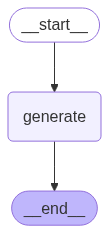

In [20]:
from IPython.display import Image, display

try:
  display(Image(graph.get_graph().draw_mermaid_png()))
except:
  pass

In [21]:
response = graph.invoke({"messages": ["안녕 안녕, 나는 왕해삼이야."]})

print(type(response))
response

<class 'dict'>


{'messages': [HumanMessage(content='안녕 안녕, 나는 왕해삼이야.', additional_kwargs={}, response_metadata={}, id='aab9fa59-203a-49d1-b016-cafb14b976f4'),
  AIMessage(content='반가워, 왕해삼아! 무엇을 도와드릴까요?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 28, 'prompt_tokens': 25, 'total_tokens': 53, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cached_tokens': 0}}, 'model_name': 'gpt-3.5-turbo-0125', 'system_fingerprint': None, 'id': 'chatcmpl-CBit8ZcrPtSLDZG5x37PLfiGwS3U7', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='run--c6c0d62b-6454-4795-9603-bc1219e14388-0', usage_metadata={'input_tokens': 25, 'output_tokens': 28, 'total_tokens': 53, 'input_token_details': {'audio': 0, 'cache_read': 0}, 'output_token_details': {'audio': 0, 'reasoning': 0}})]}

In [22]:
response["messages"].append("내 이름이 뭐라고?")
graph.invoke(response)

{'messages': [HumanMessage(content='안녕 안녕, 나는 왕해삼이야.', additional_kwargs={}, response_metadata={}, id='aab9fa59-203a-49d1-b016-cafb14b976f4'),
  AIMessage(content='반가워, 왕해삼아! 무엇을 도와드릴까요?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 28, 'prompt_tokens': 25, 'total_tokens': 53, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cached_tokens': 0}}, 'model_name': 'gpt-3.5-turbo-0125', 'system_fingerprint': None, 'id': 'chatcmpl-CBit8ZcrPtSLDZG5x37PLfiGwS3U7', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='run--c6c0d62b-6454-4795-9603-bc1219e14388-0', usage_metadata={'input_tokens': 25, 'output_tokens': 28, 'total_tokens': 53, 'input_token_details': {'audio': 0, 'cache_read': 0}, 'output_token_details': {'audio': 0, 'reasoning': 0}}),
  HumanMessage(content='내 이름이 뭐라고?', additional

In [26]:
inputs = {"messages", [("human", "한국의 걸그룹 아이브에 대해 설명해줘.")]}

for chunk, _ in graph.stream(inputs, stream_mode = "messages"):
  print(chunk.content, end="")

TypeError: unhashable type: 'list'